# EMSA: from a compartment model to sensitivity analysis

This walkthrough defines a SIR model without downloading data, solves its trajectory,
checks numerical convergence, and measures parameter sensitivity using Latin Hypercube
Sampling (LHS) and Partial Rank Correlation Coefficients (PRCC).

Install from this repository with `python -m pip install -e ".[notebook]"`, select that
Python environment as the notebook kernel, and **Run All**. The example runs on CPU.
Results are returned in memory; CSV export is optional.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import sys

# Also allow running directly from notebooks/ in a development checkout.
root = Path.cwd()
if not (root / "emsa").is_dir() and (root.parent / "emsa").is_dir():
    root = root.parent
if (root / "emsa").is_dir():
    sys.path.insert(0, str(root))

import numpy as np
import torch
import matplotlib.pyplot as plt
from emsa.model import EpidemicModel
from emsa.generics import SimulationGeneric, GenericSampler
from emsa.utils.plotter import P_VALUE_CMAP, P_VALUE_NORM, format_result_label

%matplotlib inline
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

## 1. Describe the model and population

Susceptible people become infected through contact with infected people. Infected people
recover at rate `gamma`. Here the contact matrix is 1, so the initial basic reproduction
number is approximately `beta / gamma` (before adjusting for initial susceptibles).
The state order is S, I, R. Rates and time are measured per day and in days.

For an age-structured model, provide one population per age group, a matching square
contact matrix, and age-specific parameter vectors where needed.

In [2]:
model_struct = {
    "state_data": {
        "s": {"type": "susceptible"},
        "i": {"type": "infected", "rate": "gamma"},
        "r": {"type": "recovered"},
    },
    "tms_rules": [{"source": "s", "target": "i", "actors-params": {"i": None}}],
    "trans_data": [{"source": "i", "target": "r"}],
}
data = SimpleNamespace(
    params={"beta": 0.4, "gamma": 0.15},
    age_data=torch.tensor([1000.0]),
    cm=torch.tensor([[1.0]]),
    n_age=1,
    device="cpu",
)
solver = {"method": "dopri5", "step_size": 1.0, "rtol": 1e-5, "atol": 1e-6}
model = EpidemicModel(data, model_struct, solver_config=solver)
y0 = model.get_initial_values_from_dict({"i": [10.0]})
times = torch.arange(0.0, 121.0)
solution = model.get_solution(y0, times)
trajectory = solution.ys[0].detach().cpu().numpy()
print("Solver status:", solution.status.tolist(), "(0 = success)")
print("Largest population drift:", round(float(np.max(abs(trajectory.sum(axis=1) - 1000))), 4))

Solver status: [0] (0 = success)
Largest population drift: 0.0034


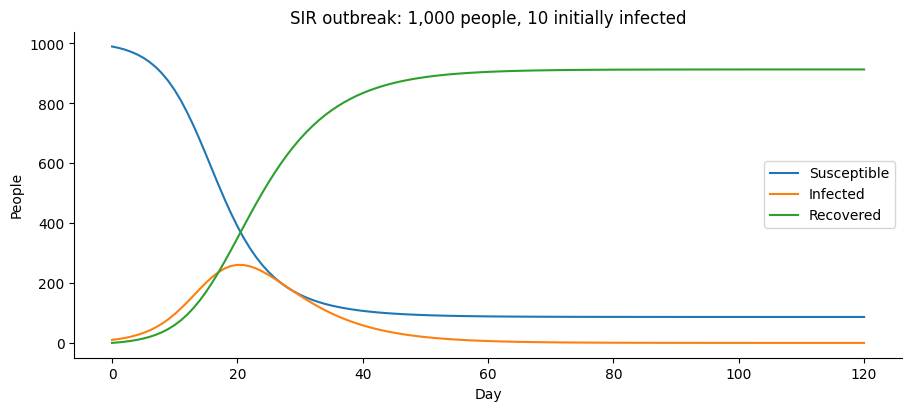

In [3]:
fig, ax = plt.subplots(layout="constrained")
for index, label in enumerate(["Susceptible", "Infected", "Recovered"]):
    ax.plot(times.numpy(), trajectory[:, index], label=label)
ax.set(xlabel="Day", ylabel="People", title="SIR outbreak: 1,000 people, 10 initially infected")
ax.legend()
plt.show()

## 2. Check the numerical resolution

The original Euler method remains available. Its one-day default is a compatibility
setting, and fast dynamics can require smaller steps. Compare results at successively
smaller steps; the differences should shrink. Dopri5 is adaptive, with `step_size` as
its maximum step size. A separate test compares its trajectory with SciPy `solve_ivp`.

The package raises errors for solver failure, non-finite populations, or materially
negative populations instead of silently returning those results. Tiny negative values
within the absolute `negative_tolerance` are retained, not clipped. For interventions
with time discontinuities, check resolution around the intervention times too.

In [4]:
reference = trajectory
print("Euler step (days) | maximum difference from Dopri5 (people)")
for step in [1.0, 0.5, 0.25]:
    values = model.get_solution(y0, times, solver_config={"method": "euler", "step_size": step}).ys[0]
    error = np.max(np.abs(values.detach().cpu().numpy() - reference))
    print(f"{step:17.2f} | {error:.3f}")

Euler step (days) | maximum difference from Dopri5 (people)
             1.00 | 60.054


             0.50 | 30.055


             0.25 | 14.969


## 3. Run reproducible sensitivity analysis

Sample `beta` and `gamma` independently within the ranges below.
`i_max` is the largest total infected population observed on the daily evaluation grid.
`r_sup` is the recovered population at the first completed evaluation window where fewer
than one infected person remains; it approximates the final epidemic size.

The calculator extends unfinished trajectories up to `tlim_final`, raising an error if
any sample remains unfinished. Peaks use the highest observed daily value, rather than
continuous-time optimization. PRCC measures conditional monotonic association, not causality.
The 256 samples here keep the demo short; check stability with larger samples for analysis.

In [5]:
sampling_config = {
    "target_vars": ["i_max", "r_sup"],
    "sampled_params_boundaries": {"beta": [0.3, 0.5], "gamma": [0.1, 0.2]},
    "n_samples": 256,
    "batch_size": 64,
    "init_vals": {"i": [10.0]},
    "seed": 42,
    "solver": solver,
    "tlim_ini": 150,
    "tlim_final": 1000,
    "tdelta": 50,
}
simulation = SimulationGeneric(data, model_struct, sampling_config, save_results=False)
results = simulation.run()
# An empty scenario name means no fixed-parameter scenarios were requested.
result = results[""]
print("Sample table:", result["samples"].shape)
print("Targets:", list(result["targets"]))
print("Seed:", result["metadata"]["seed"])
for target in sampling_config["target_vars"]:
    print(target, "PRCC:", result["prcc"][target], "p-values:", result["p_values"][target])


 Simulation for 256 samples ()
Batch size: 64


 Time limit: 150 
 Samples left: 256 

 Solving batch 1 / 4


 Solving batch 2 / 4


 Solving batch 3 / 4


 Solving batch 4 / 4



 Elapsed time:  2.631368398666382
Sample table: (256, 2)
Targets: ['i_max', 'r_sup']
Seed: 42
i_max PRCC: [ 0.9728656  -0.98500486] p-values: [7.61989365e-163 4.27604879e-195]
r_sup PRCC: [ 0.97285845 -0.98497338] p-values: [7.87438218e-163 5.56404448e-195]


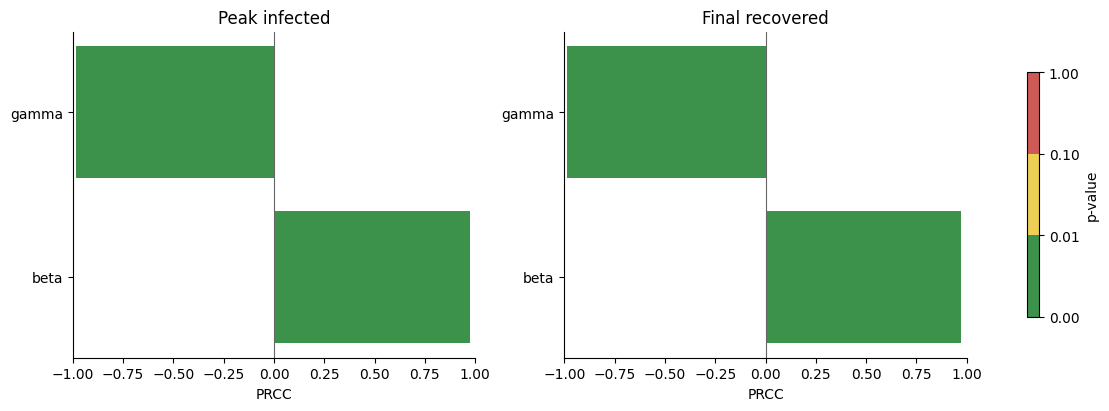

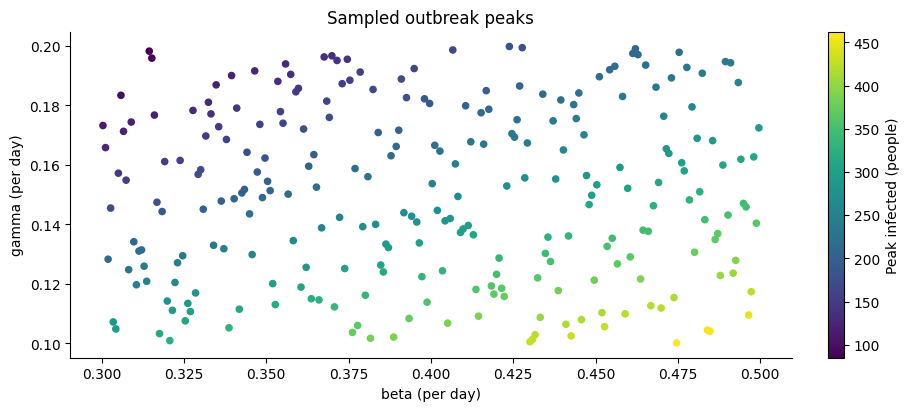

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
parameter_names = list(sampling_config["sampled_params_boundaries"])
for ax, target in zip(axes, sampling_config["target_vars"]):
    coefficients = result["prcc"][target]
    ax.barh(parameter_names, coefficients, color=P_VALUE_CMAP(P_VALUE_NORM(result["p_values"][target])))
    ax.axvline(0, color="0.4", linewidth=0.8)
    ax.set(xlim=(-1, 1), xlabel="PRCC", title=format_result_label(target))
fig.colorbar(plt.cm.ScalarMappable(norm=P_VALUE_NORM, cmap=P_VALUE_CMAP),
             ax=axes, shrink=0.75, label="p-value", ticks=[0, 0.01, 0.1, 1])
plt.show()

fig, ax = plt.subplots(layout="constrained")
points = ax.scatter(result["samples"][:, 0], result["samples"][:, 1],
                    c=result["targets"]["i_max"], cmap="viridis", s=20)
ax.set(xlabel="beta (per day)", ylabel="gamma (per day)", title="Sampled outbreak peaks")
fig.colorbar(points, ax=ax, label="Peak infected (people)")
plt.show()

Higher transmission increases the peak; faster recovery decreases it. PRCC magnitude
near one indicates a strong conditional monotonic association within these selected ranges.
Changing the ranges can change the coefficients. P-values use `n_samples - n_inputs - 1`
degrees of freedom. Undefined conditional coefficients are reported as NaN with a warning;
constant or rank-dependent inputs are rejected.

## 4. Reproduce samples and optionally export

The seed fixes the LHS sample table. Device, numerical settings and dependency versions
also affect reproducibility. Results retain the input configuration, population, contact
matrix, baseline parameters, solver settings, package version and seed as metadata.

In [7]:
repeated_samples = GenericSampler(simulation).get_lhs_table()
np.testing.assert_array_equal(repeated_samples, result["samples"])
print("The same seed reproduces the sample table exactly.")
print("Result fields:", list(result))

# Optional file export: explicitly enable and rerun in a chosen directory.
# exported = SimulationGeneric(data, model_struct, sampling_config,
#                              output_dir="demo_results", save_results=True).run()
# This writes CSV files plus metadata.json (or metadata_<scenario>.json).
# Use a fresh directory for separate concurrent runs: matching filenames are replaced.

The same seed reproduces the sample table exactly.
Result fields: ['samples', 'targets', 'metadata', 'prcc', 'p_values']


## Next steps

Try changing `beta`, `gamma`, or the sampling ranges, then increase the sample count and
compare PRCC stability. See `emsa_examples/` for SEIR, SEIHR, contact reduction and vaccine
allocation examples. A React application can consume these in-memory results through a
separate API layer. Convert NumPy arrays to lists and undefined statistics to JSON `null`
in that layer. This notebook does not start a server or deploy a service.